<a href="https://colab.research.google.com/github/CristhoferT29/sabana-transport-clustering/blob/main/Actividad_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


# Ruta del archivo CSV
url = (
    "https://raw.githubusercontent.com/"
    "CristhoferT29/sabana-transport-clustering/"
    "main/data/rutas_sabana_kmeans.csv"
)

df = pd.read_csv(url)

# Mostrar información general
print("Primeros registros:")
print(df.head())

print("\nDimensiones del dataset:")
print(df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores nulos por columna:")
print(df.isnull().sum())

print("\nEstadísticas descriptivas:")
print(df.describe())

Primeros registros:
   id_ruta origen destino  distancia_km  duracion_min  pasajeros_dia  \
0        1  Funza    Cota            18            39            550   
1        2  Funza    Cota            18            46            810   
2        3  Funza    Cota            18            53            410   
3        4  Funza    Cota            18            43            660   
4        5   Cota    Chia            12            30            655   

   frecuencia_min    escenario  
0              20  escenario_1  
1              12  escenario_2  
2              30  escenario_3  
3              17  escenario_4  
4              23  escenario_1  

Dimensiones del dataset:
(32, 8)

Tipos de datos:
id_ruta            int64
origen            object
destino           object
distancia_km       int64
duracion_min       int64
pasajeros_dia      int64
frecuencia_min     int64
escenario         object
dtype: object

Valores nulos por columna:
id_ruta           0
origen            0
destino         

In [8]:
# Seleccionar las características para K-Means
columnas = [
    "distancia_km",
    "duracion_min",
    "pasajeros_dia",
    "frecuencia_min"]

X = df[columnas]

# Estandarizar las características
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Mostrar los primeros registros transformados
df_scaled = pd.DataFrame(X_scaled, columns=columnas)

print("\nDatos estandarizados:")
print(df_scaled.head())

print("\nPromedio de las variables estandarizadas:")
print(df_scaled.mean().round(4))


Datos estandarizados:
   distancia_km  duracion_min  pasajeros_dia  frecuencia_min
0      0.615882     -0.331547      -1.508269       -0.340427
1      0.615882      0.442063      -0.585563       -1.487130
2      0.615882      1.215674      -2.005110        1.092951
3      0.615882      0.110516      -1.117893       -0.770441
4     -0.727860     -1.326190      -1.135638        0.089586

Promedio de las variables estandarizadas:
distancia_km     -0.0
duracion_min     -0.0
pasajeros_dia     0.0
frecuencia_min    0.0
dtype: float64


In [9]:

# Crear el modelo con 3 grupos
modelo = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Entrenar el modelo y obtener los grupos
clusters = modelo.fit_predict(X_scaled)

# Agregar los grupos al dataset original
df["cluster"] = clusters

# Mostrar los resultados
print("Rutas agrupadas:")
print(df[[
    "origen",
    "destino",
    "distancia_km",
    "duracion_min",
    "pasajeros_dia",
    "frecuencia_min",
    "cluster"
]].head(15))

print("\nCantidad de registros por grupo:")
print(df["cluster"].value_counts().sort_index())


Rutas agrupadas:
   origen destino  distancia_km  duracion_min  pasajeros_dia  frecuencia_min  \
0   Funza    Cota            18            39            550              20   
1   Funza    Cota            18            46            810              12   
2   Funza    Cota            18            53            410              30   
3   Funza    Cota            18            43            660              17   
4    Cota    Chia            12            30            655              23   
5    Cota    Chia            12            37            915              15   
6    Cota    Chia            12            44            515              33   
7    Cota    Chia            12            34            765              20   
8    Chia  Cajica            10            29            760              26   
9    Chia  Cajica            10            36           1020              18   
10   Chia  Cajica            10            43            620              36   
11   Chia  Cajica      

In [10]:

# Calcular las características promedio de cada cluster
resumen = df.groupby("cluster")[[
    "distancia_km",
    "duracion_min",
    "pasajeros_dia",
    "frecuencia_min"
]].mean().round(2)

print("Características promedio por cluster:")
print(resumen)

# Mostrar los registros de cada cluster
for cluster in sorted(df["cluster"].unique()):
    print(f"\n--- Cluster {cluster} ---")

    rutas = df[df["cluster"] == cluster]

    print(rutas[[
        "origen",
        "destino",
        "escenario",
        "distancia_km",
        "duracion_min",
        "pasajeros_dia",
        "frecuencia_min"
    ]].to_string(index=False))


Características promedio por cluster:
         distancia_km  duracion_min  pasajeros_dia  frecuencia_min
cluster                                                           
0                9.80         31.20         993.50           20.40
1               18.40         44.67        1072.33           18.73
2               16.29         51.71         740.00           33.00

--- Cluster 0 ---
origen   destino   escenario  distancia_km  duracion_min  pasajeros_dia  frecuencia_min
  Cota      Chia escenario_1            12            30            655              23
  Cota      Chia escenario_2            12            37            915              15
  Cota      Chia escenario_4            12            34            765              20
  Chia    Cajica escenario_1            10            29            760              26
  Chia    Cajica escenario_2            10            36           1020              18
  Chia    Cajica escenario_4            10            33            870         

In [11]:


resultados = []

# Evaluar diferentes cantidades de clusters
for k in range(2, 9):
    modelo_k = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo_k.fit_predict(X_scaled)

    puntuacion = silhouette_score(
        X_scaled,
        etiquetas
    )

    resultados.append({
        "k": k,
        "silhouette": round(puntuacion, 4)
    })

resultados_df = pd.DataFrame(resultados)

print("Evaluación de diferentes valores de K:")
print(resultados_df)

mejor = resultados_df.loc[
    resultados_df["silhouette"].idxmax()
]

print(
    f"\nMejor K evaluado: {int(mejor['k'])}"
)


Evaluación de diferentes valores de K:
   k  silhouette
0  2      0.3170
1  3      0.3645
2  4      0.3429
3  5      0.3429
4  6      0.3643
5  7      0.3273
6  8      0.3602

Mejor K evaluado: 3


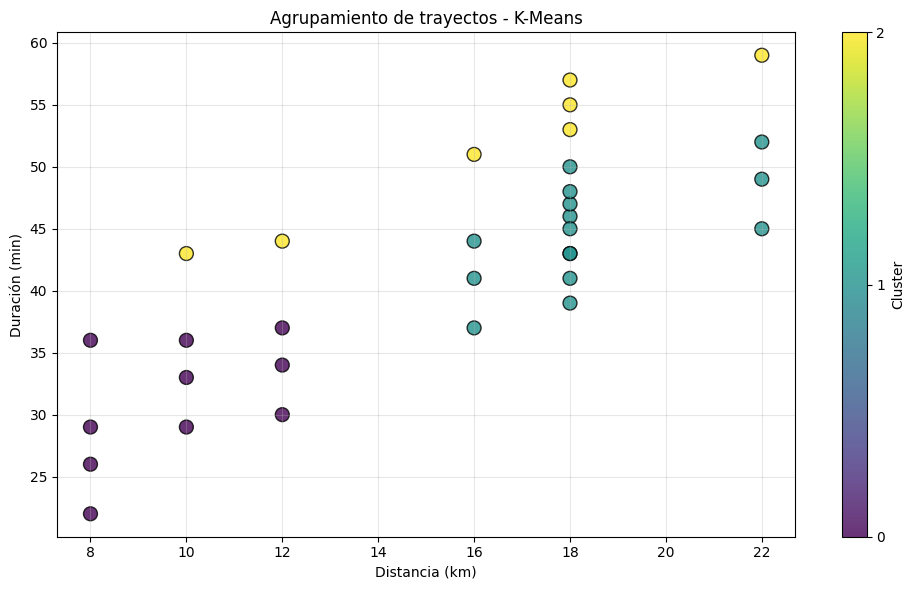

In [12]:


plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["distancia_km"],
    df["duracion_min"],
    c=df["cluster"],
    cmap="viridis",
    s=100,
    alpha=0.8,
    edgecolors="black"
)

plt.xlabel("Distancia (km)")
plt.ylabel("Duración (min)")
plt.title("Agrupamiento de trayectos - K-Means")

plt.colorbar(
    scatter,
    ticks=[0, 1, 2],
    label="Cluster"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "clusters_rutas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:

# Exportar el dataset con los grupos asignados
df.to_csv(
    "rutas_sabana_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Resultados exportados correctamente")


Resultados exportados correctamente
